In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

c:\Users\Md mansoor ali khan\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:109: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.4.3)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


Step 2: Load MNIST dataset

In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


MNIST contains 60,000 training images and 10,000 testing images. 
keras

Step 3: Display sample images

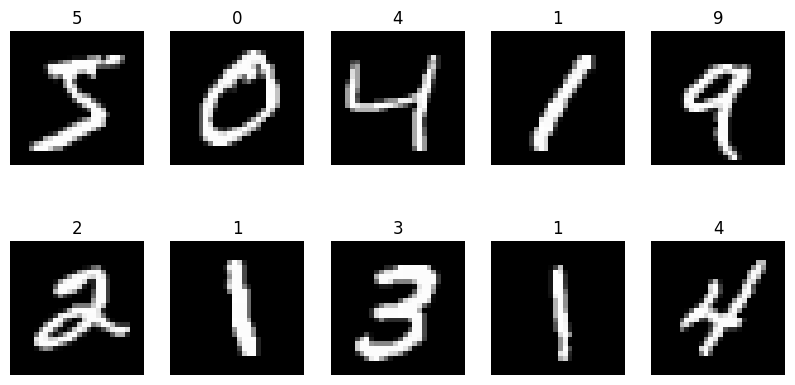

In [4]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')

plt.show()

Step 4: Preprocess the data

In [5]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

x_train = x_train / 255.0
x_test = x_test / 255.0

Why?
- Reshape adds one channel because MNIST images are grayscale.
- Dividing by 255 normalizes pixel values between 0 and 1

Step 5: Build CNN model

In [6]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(10, activation='softmax')
])

c:\Users\Md mansoor ali khan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Step 6: Display model summary

In [7]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Step 7: Compile the model

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Step 8: Train the model

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9193 - loss: 0.2705 - val_accuracy: 0.9798 - val_loss: 0.0696
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9754 - loss: 0.0822 - val_accuracy: 0.9858 - val_loss: 0.0496
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9828 - loss: 0.0563 - val_accuracy: 0.9885 - val_loss: 0.0388
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9857 - loss: 0.0460 - val_accuracy: 0.9907 - val_loss: 0.0387
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9878 - loss: 0.0380 - val_accuracy: 0.9908 - val_loss: 0.0349
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9899 - loss: 0.0332 - val_accuracy: 0.9903 - val_loss: 0.0342
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9918 - loss: 0.0266 - val_accuracy: 0.9918 - val_loss: 0.0332
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9919 - loss: 0.0250 - val_accu

Step 9: Evaluate the model

In [10]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9903 - loss: 0.0288
Test Loss: 0.028804846107959747
Test Accuracy: 99.02999997138977 %


Step 10: Plot accuracy and loss

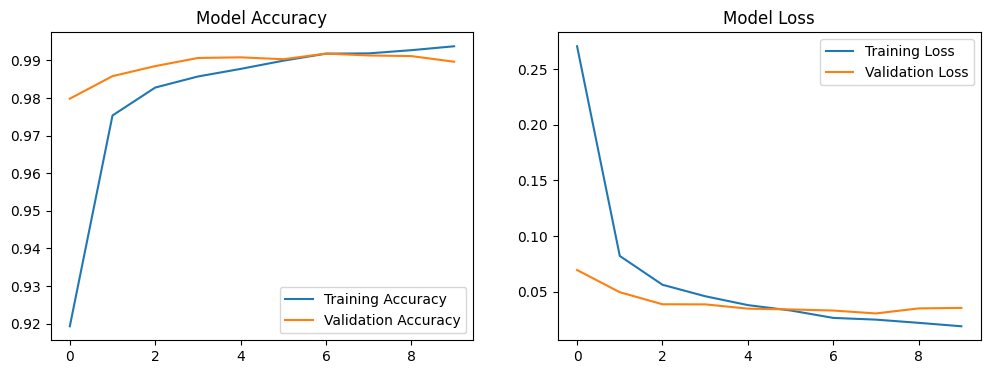

In [11]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.legend()

plt.show()

Step 11: Test with a sample image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Predicted Digit: 7
Actual Digit: 7


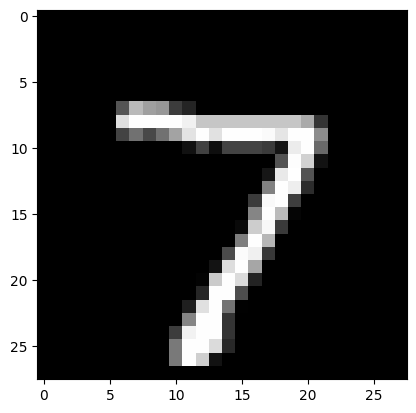

In [12]:
prediction = model.predict(x_test[:1])

print("Predicted Digit:", np.argmax(prediction))
print("Actual Digit:", y_test[0])

plt.imshow(x_test[0].reshape(28,28), cmap='gray')
plt.show()

Step 12: Predict all test images

In [13]:
predictions = model.predict(x_test)

predicted_labels = np.argmax(predictions, axis=1)

print("Total Test Images:", len(x_test))
print("Total Predictions:", len(predicted_labels))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Total Test Images: 10000
Total Predictions: 10000


Step 13: Calculate correct and incorrect predictions

In [14]:
correct = np.sum(predicted_labels == y_test)
incorrect = np.sum(predicted_labels != y_test)

print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Accuracy:", (correct / len(y_test)) * 100, "%")

Correct Predictions: 9903
Incorrect Predictions: 97
Accuracy: 99.03 %


Step 14: Display all misclassified images

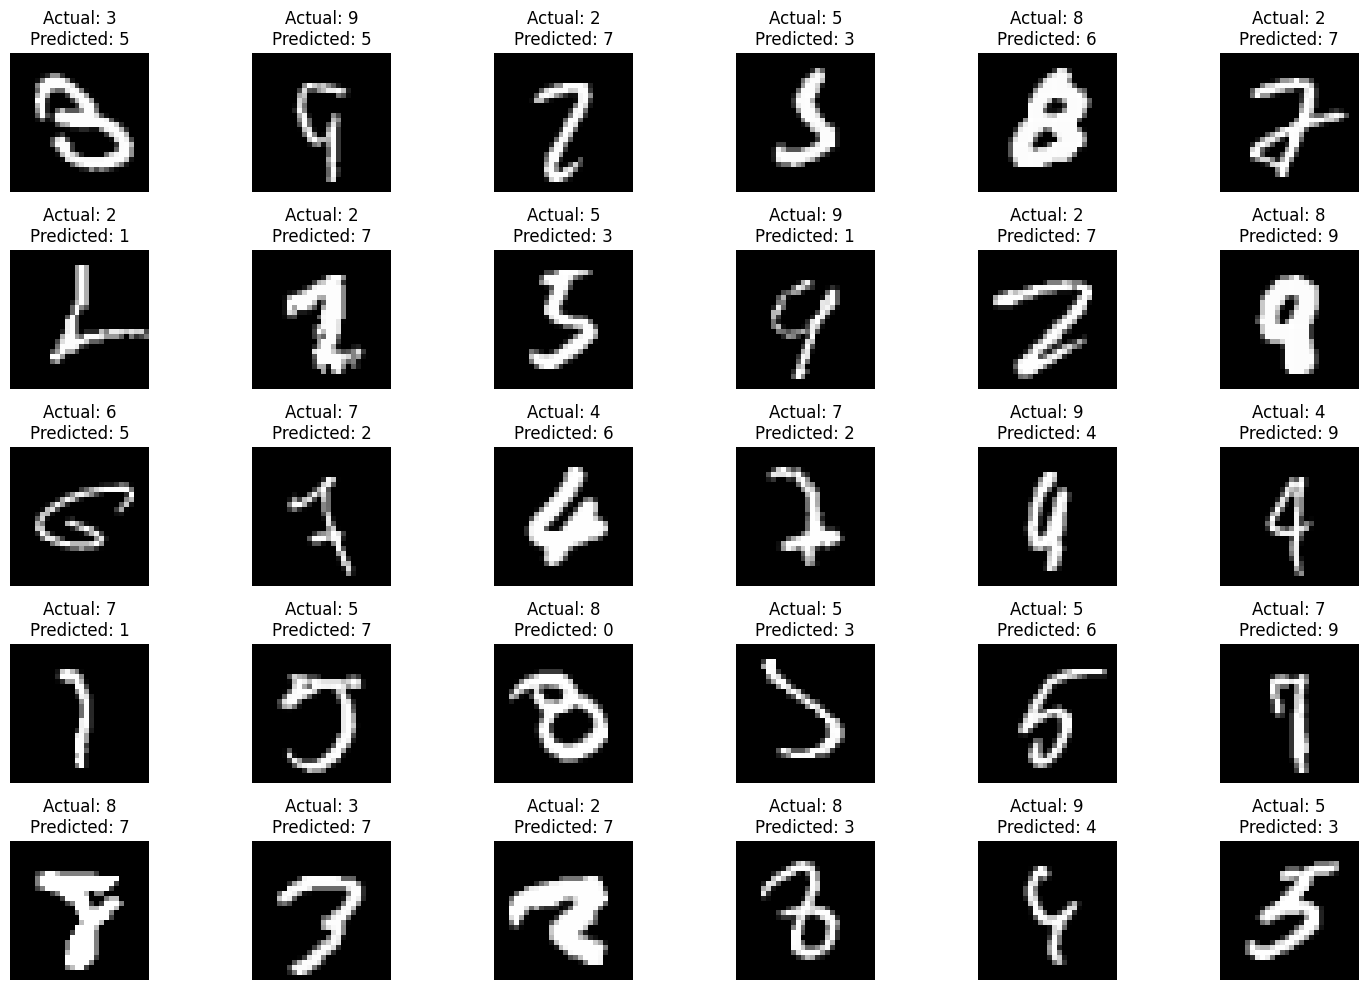

In [15]:
wrong = np.where(predicted_labels != y_test)[0]

plt.figure(figsize=(15, 10))

for i, index in enumerate(wrong[:30]):
    plt.subplot(5, 6, i+1)
    plt.imshow(x_test[index].reshape(28, 28), cmap='gray')
    plt.title(f"Actual: {y_test[index]}\nPredicted: {predicted_labels[index]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Step 15: Display prediction results for all 10,000 images

In [16]:
import pandas as pd

results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': predicted_labels,
    'Result': np.where(predicted_labels == y_test, 'Correct', 'Incorrect')
})

display(results)

,Actual,Predicted,Result
0,7,7,Correct
1,2,2,Correct
2,1,1,Correct
3,0,0,Correct
4,4,4,Correct
...,...,...,...
9995,2,2,Correct
9996,3,3,Correct
9997,4,4,Correct
9998,5,5,Correct


Step 16: Accuracy for each digit

In [17]:
for digit in range(10):
    total = np.sum(y_test == digit)
    correct = np.sum((y_test == digit) & (predicted_labels == digit))
    accuracy = (correct / total) * 100

    print(f"Digit {digit}: {correct}/{total} | Accuracy: {accuracy:.2f}%")

Digit 0: 977/980 | Accuracy: 99.69%
Digit 1: 1133/1135 | Accuracy: 99.82%
Digit 2: 1015/1032 | Accuracy: 98.35%
Digit 3: 1002/1010 | Accuracy: 99.21%
Digit 4: 978/982 | Accuracy: 99.59%
Digit 5: 876/892 | Accuracy: 98.21%
Digit 6: 950/958 | Accuracy: 99.16%
Digit 7: 1019/1028 | Accuracy: 99.12%
Digit 8: 963/974 | Accuracy: 98.87%
Digit 9: 990/1009 | Accuracy: 98.12%


Step 17: Display digit-wise accuracy in a bar graph

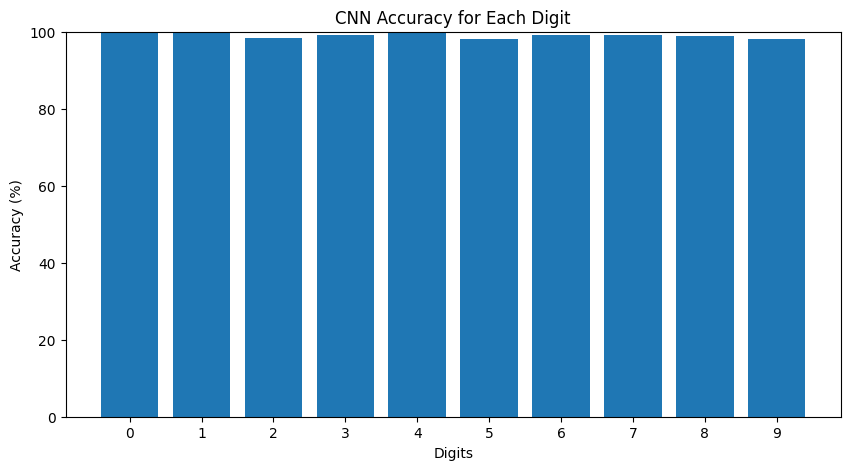

In [18]:
digit_accuracy = []

for digit in range(10):
    total = np.sum(y_test == digit)
    correct = np.sum((y_test == digit) & (predicted_labels == digit))
    digit_accuracy.append((correct / total) * 100)

plt.figure(figsize=(10,5))
plt.bar(range(10), digit_accuracy)
plt.xlabel("Digits")
plt.ylabel("Accuracy (%)")
plt.title("CNN Accuracy for Each Digit")
plt.xticks(range(10))
plt.ylim(0, 100)
plt.show()

Step 18: Generate classification report

In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predicted_labels))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.98      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



This gives you:
- Precision: How many predictions of a digit were correct.
- Recall: How many actual images of that digit were identified correctly.
- F1-score: Combined measure of precision and recall.

Step 19: Confusion matrix

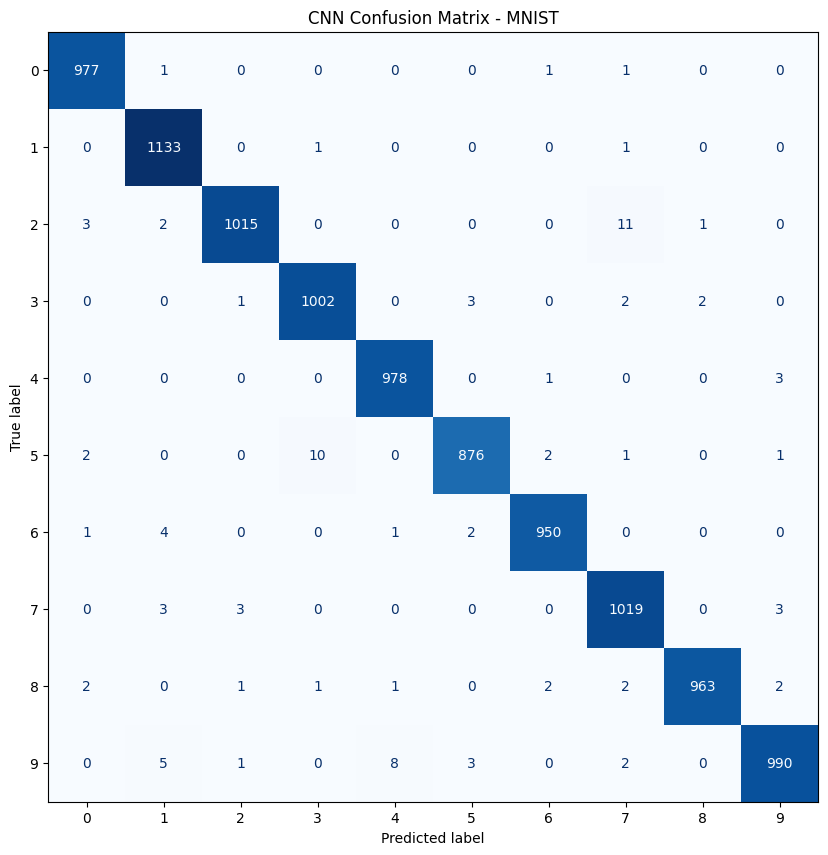

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted_labels)

plt.figure(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap='Blues', ax=plt.gca(), colorbar=False)

plt.title("CNN Confusion Matrix - MNIST")
plt.show()

Step 20: Test all 10 digits

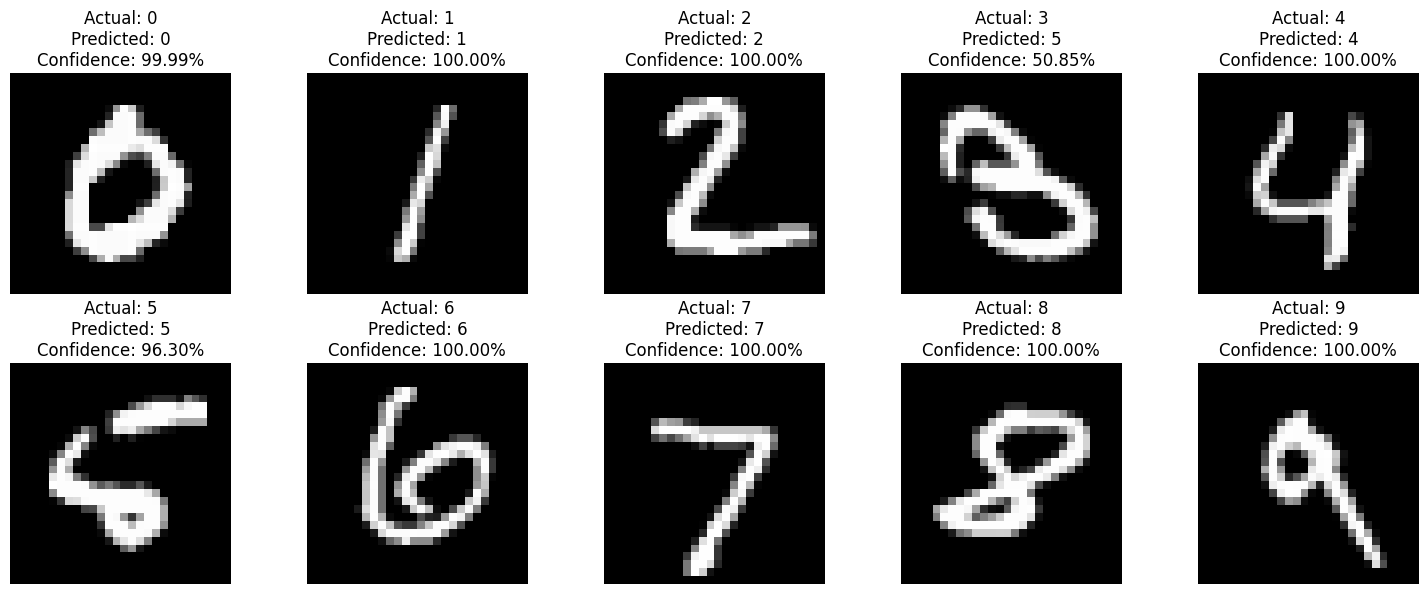

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Select one image for each digit (0-9)
plt.figure(figsize=(15, 6))

for digit in range(10):

    index = np.where(y_test == digit)[0][0]

    image = x_test[index]

    prediction = model.predict(image.reshape(1, 28, 28, 1), verbose=0)

    predicted_digit = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    plt.subplot(2, 5, digit + 1)
    plt.imshow(image.reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {digit}\n"
        f"Predicted: {predicted_digit}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

Step 21: Create your own handwritten digit predictor

In [23]:
!pip install pillow


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Step 22: Drawing application with CNN prediction

In [26]:
import tkinter as tk
from PIL import Image, ImageDraw
import numpy as np

# Create drawing window
root = tk.Tk()
root.title("MNIST - CNN Digit Predictor")

# Drawing area
canvas = tk.Canvas(root, width=280, height=280, bg="black")
canvas.pack()

# Create black image
image = Image.new("L", (280, 280), 0)
draw = ImageDraw.Draw(image)

# Drawing function
def paint(event):
    x, y = event.x, event.y

    canvas.create_oval(x-10, y-10, x+10, y+10,
                       fill="white", outline="white")

    draw.ellipse((x-10, y-10, x+10, y+10), fill=255)

canvas.bind("<B1-Motion>", paint)

# Prediction function
def predict():

    img = image.resize((28, 28), Image.Resampling.LANCZOS)

    img_array = np.array(img) / 255.0

    img_array = img_array.reshape(1, 28, 28, 1)

    prediction = model.predict(img_array, verbose=0)

    digit = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    result.config(
        text=f"Predicted Digit: {digit}\nConfidence: {confidence:.2f}%"
    )

# Clear function
def clear():

    canvas.delete("all")
    draw.rectangle((0, 0, 280, 280), fill=0)

    result.config(text="Draw a digit")

# Buttons
tk.Button(root, text="Predict", command=predict,
          font=("Arial", 14)).pack(pady=5)

tk.Button(root, text="Clear", command=clear,
          font=("Arial", 14)).pack(pady=5)

# Result
result = tk.Label(root, text="Draw a digit",
                  font=("Arial", 16))

result.pack(pady=10)

# Run application
root.mainloop()